# Flux post-processing chain: IRGA72 latent heat flux (2016-2026.09)

**notebook version**: `1` (26 Oct 2026). Built from the CO2-flux notebook of this folder
(`01_FPPC_IRGA72_NEE_2016-2026.09`), which is adapted from the diive notebook
`FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

This notebook processes the latent heat flux (`LE`) of the closed-path **IRGA72** analyser (LI-7200)
for the release **FP2026.1** (2016 to September 2026). It removes poor-quality records and outliers,
fills the gaps, and converts the gap-filled flux to evapotranspiration (ET). The steps follow the
levels of the Swiss FluxNet workflow:

| Level | What it does | Function |
|---|---|---|
| L2 | Quality flags from the EddyPro output | `run_level2` |
| L3.1 | No storage term: the term is set to zero | `run_level31` |
| L3.2 | Removes outliers | `make_level32_detector` + `run_level32` |
| L3.3 | No USTAR filter: one scenario with a threshold of 0 | `run_level33_constant_ustar` |
| L4.1 | Fills the gaps with XGBoost and with MDS | `run_level41_xgb`, `run_level41_mds` |
| | Converts the gap-filled LE to ET | `et_from_le` |

Each step takes the data and returns a new copy, so a step can be repeated without running the
earlier ones again.

The notebook runs on the whole record (`YEARS = None`). A list of years in `YEARS` runs a test on
those years only and writes its own output file.

The energy fluxes are processed as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020): without a
storage term, without USTAR filtering, and without partitioning. This version of the dataset gives
no uncertainty for LE and no version corrected for the energy balance closure.

Compared with the 2016-2024 LE notebooks in this folder (`11_FPC_L3.3_…` and `13_FPC_L4.1_…`),
Level 2 and the absolute limits are unchanged, and both run Level 3.3 with a single threshold of 0
(there named `NONE`, here `CUT_NONE`). The other steps differ: the single-point storage term
`SLE_SINGLE` is no longer added (Level 3.1); the periods removed by hand include three gas-analyser
faults in 2018-2019 and 2020, and the two Hampel filters of the CO2-flux notebook replace the
Hampel filters and the local standard deviation test of the earlier chain (Level 3.2); and the gaps
are filled with XGBoost and MDS instead of a random forest (Level 4.1).

***

## 📇 Data sources

The input is `30_FLUX_PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` in the
external data folder. It holds the Level-1 fluxes of all 18 `IRGA72` runs together with the meteo
data of `10_METEO/30_PRODUCTS/99`, from 1 January 2016 00:15 to 30 September 2026 23:45
(`TIMESTAMP_MIDDLE`, UTC+01:00). The flux columns are empty before the first `IRGA72` record on
11 January 2016.

**Meteo drivers.** Gap-filling uses three complete meteo series: air temperature
(`TA_T1_47_1_HOMOGENIZED_gfXG`), vapour pressure deficit (`VPD_T1_47_1_HOMOGENIZED`) and incoming
shortwave radiation (`SW_IN_T1_47_1_gfXG`). Temperature and VPD are the homogenised versions, which
correct for the probe changes in 2016 and June 2026. The air temperature also gives the latent heat
of vaporization for the conversion to ET (Step 11).

**Periods to keep in mind.** The faults of the gas analyser affect `LE` as well as `FC`, since the
LI-7200 measures H2O and CO2 in the same cell. Each period removed by hand was checked in `LE`
itself. A day-by-day scan of the Level-2 records compares four measures with their seasonal level:
the scatter at night, the scatter of consecutive records, the values outside the absolute limits,
and the values above the incoming shortwave radiation. It finds November 2020 as by far the
strongest episode of the record. The other flagged episodes last a few days, have no instrument
cause in the fieldbook, and are left to the outlier tests.

- **Start-up of the LI-7200 in 2016.** During the installation (11 to 22 January), `LE` is close to
  zero (daily 95th percentile below 1 W m-2 until 21 January). From 1 March to 25 May the flow rate
  was about 1.4 L min-1 instead of about 13 L min-1, and water was found in the filter. The daily
  95th percentile of `LE` stayed mostly below 130 W m-2 and rose to 360-430 W m-2 on 26 and 27 May,
  after the flow rate was restored. Level 3.2 removes both periods by hand, as the 2016-2024
  notebooks did.
- **19 May to 7 June 2018.** There is no `LE`. The flow module of the analyser had failed, so this
  period was processed with the sonic anemometer only.
- **30 December 2018 to 10 January 2019.** The LI-7200 (IRGA72-B) was failing: its signal strength
  was low from December, the inlet filter was iced, it sent error codes, and its data acquisition
  stopped repeatedly. It was replaced on 11 January 2019. Records of this period pass Level 2 with
  `LE` spikes that coincide with spikes in `FC` (3 January, 10:45: 294 W m-2 and
  185 µmol m-2 s-1), and with `LE` of 94 W m-2 at dusk, at 17 W m-2 incoming radiation and -2 °C.
  Level 3.2 removes the period by hand.
- **8 November to 6 December 2020.** A fault of the gas analyser, with normal flow rate and normal
  sonic (`H`). From 8 November, `LE` rose with the impossible positive daytime `FC` of the fault,
  for example to 361 W m-2 at 239 W m-2 incoming radiation, together with 234 µmol m-2 s-1 `FC`
  (8 November, 10:45). Until 27 November the daily 95th percentile of `LE` was 130-440 W m-2 at
  0-10 °C, on five days above that of the incoming radiation, and the scatter at night reached up to
  50 times its seasonal level. The signal strength fell from 100 to about 60 on 12 November, the
  threshold of Level 2, rose to 80 on 27 November and to 100 after the LI-7200 was replaced on
  10 December. From 28 November to 3 December `LE` is plausible (daily 95th percentile
  9-26 W m-2). From 4 to 6 December it is again above the incoming radiation (daily 95th
  percentile 83-176 W m-2 at 75-118 W m-2 incoming radiation and about 0.5 °C). Level 3.2 removes
  8 to 27 November and 4 to 6 December by hand, the same windows as for `FC`.
- **15 January to 4 February 2026.** In `FC` the nighttime scatter was about twice its seasonal
  level, also after the outlier tests, with winter daytime values above 20 µmol m-2 s-1, until the
  LI-7200 was cleaned on 4 February 2026. The signal strength fell from 93 to 87 on 28 January and
  returned to 100 after the cleaning. Level 3.2 removes the same period from `LE` by hand, as for
  `FC`.
- **Long gaps without `LE`.** The model fills these gaps without measurements nearby: 1 to
  22 January 2016 (before and during the installation), 1 March to 25 May 2016 (removed by hand),
  19 May to 7 June 2018 (flow module), 30 December 2018 to 20 March 2019 (the failing LI-7200, then
  both units defective and the LI-7500 as a stand-in, whose fluxes are not part of this dataset),
  8 to 27 November 2020 (removed by hand), 18 December 2020 to 4 January 2021, 13 December 2021
  to 7 February 2022 (raw data that cannot be converted), and 15 January to 4 February 2026
  (removed by hand).

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# Years to process. None processes the whole record. A test run writes its own output file, so it
# never overwrites the result of a full run.
YEARS = None

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "11_FPPC_IRGA72_LE_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\IRGA72"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'LE'  # latent heat flux of the closed-path LI-7200 (W m-2), without storage term
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
# The VM97 test reads H2O_VM97_TEST, the SSITC and SCF tests LE_SSITC_TEST and LE_SCF.
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
LEVEL2_INPUTS = ['LE_SSITC_TEST', 'LE_SCF', 'H2O_VM97_TEST']

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The evidence in LE is in
# *Data sources*.
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],  # LI-7200 installation, water in the filter: LE close to zero
    ['2016-03-01', '2016-05-25'],  # too low a flow rate, water in the filter: LE far too low
    ['2018-12-30', '2019-01-10'],  # failing LI-7200 (IRGA72-B): LE spikes together with FC spikes
    ['2020-11-08', '2020-11-27'],  # gas analyser fault: LE above incoming radiation, night scatter
    ['2020-12-04', '2020-12-06'],  # same fault, before the LI-7200 was replaced on 10 December
    ['2026-01-15', '2026-02-04'],  # raised scatter until the LI-7200 was cleaned on 4 February
]
# Absolute limits (W m-2), as in the 2016-2024 LE notebook. See Step 4.
ABSLIM = (-50, 800)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for LE. The chain needs Level 3.3 before gap-filling, so it runs with a single
# scenario at a threshold of 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
USTAR_SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete; also used for ET
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min LE in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
W_TO_MJ = 1800 / 1e6

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=350, max_depth=6, learning_rate=0.05,
                    early_stopping_rounds=10, random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Evapotranspiration ------------------------------------------------------------------------
# et_from_le returns mm h-1; times this factor gives mm per half-hour.
HOURS_PER_RECORD = 0.5

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
)
from diive.variables.thermodynamic import et_from_le

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-26 15:44:15
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG, *LEVEL2_INPUTS,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet (0.285 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
LE: 174,988 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: LE ────────────────────────────────────

> Detected base variable H2O for LE. (H2O was used to calculate LE.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'LE'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [LE, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The same tests as in the 2016-2024 notebooks: steady state and developed turbulence (SSITC of
`LE`), the size of the spectral correction factor of `LE`, the signal strength of the LI-7200
(records below 60 are removed), and spikes and dropouts in the raw H2O data (Vickers and Mahrt
1997). Gas completeness is not tested. Over 2016-2026.09, SSITC rejects about 24 % of the `LE`
records, the signal strength about 1 %, the spike test about 1,100 records and the spectral
correction factor about 400; the dropout test never fails.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_LE_SSITC_TEST, values taken from output variable
LE_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_LE_SCF_TEST, newly 
calculated from output variable LE_SCF, with flag 0 (good values) where LE_SCF < 2, flag 1 (ok 
values) where LE_SCF >= 2 and < 4, flag 2 (bad values) where LE_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_LE_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_SPIKE_HF_TEST, values taken from 
output variable H2O_VM97_TEST from position 1, based on H2O, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_DROPOUT_HF_TEST, values taken 
from output variable H2O_VM97_TEST from position 3, based on H2O, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 130,543 valid records


### 📊 Plot: Level-2 quality flag over time

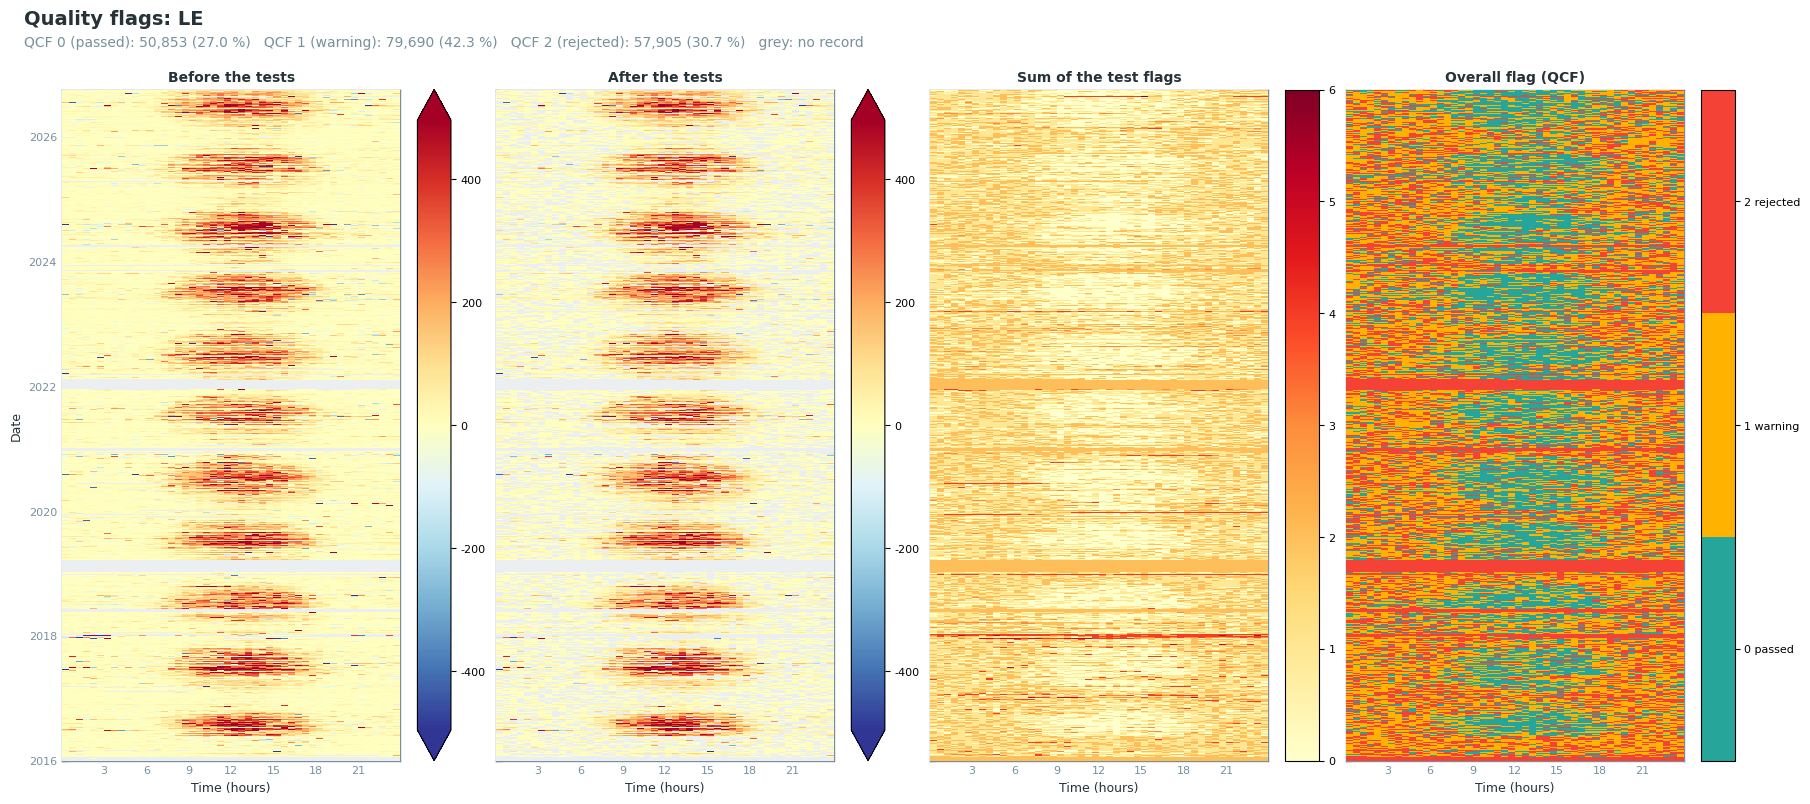

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: LE
Measured records: 174,988 of 188,448
Missing records: 13,460 (7.14 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                 all      174,988    52,194   80,020   42,774   24.44        0
                            day       88,841    38,869   35,939   14,033   15.80        0
                            night     86,147    13,325   44,081   28,741   33.36        0
                                                                                         
L2_LE_SCF                   all      174,988   169,971    4,613      404    0.23        0
                            day       88,841    86,446    2,170      225    0.25        0
                            night     86,147    83,525    2,443      179    0.21        0
                                                                                         
L2_LE_SIGNAL_STRENGTH       all      174,988   173,685        0    1,303    0.74        0
                            day       88,841    88,297        0      544    0.61        0
                            night     86,147    85,388        0      759    0.88        0
                                                                                         
L2_LE_H2O_VM97_SPIKE_HF     all      174,988   173,870        0    1,118    0.64        0
                            day       88,841    88,376        0      465    0.52        0
                            night     86,147    85,494        0      653    0.76        0
                                                                                         
L2_LE_H2O_VM97_DROPOUT_HF   all      174,988   174,988        0        0    0.00        0
                            day       88,841    88,841        0        0    0.00        0
                            night     86,147    86,147        0        0    0.00        0

## Step 3: no storage term (Level 3.1)

No storage term is added. FLUXNET2015 and ONEFlux take H and LE as turbulent fluxes without a
storage correction (Pastorello et al. 2020), so the single-point storage term `SLE_SINGLE` of the
input is not used. Level 3.1 still runs, with `set_storage_to_zero=True`, because the later levels
of the chain require it: it adds zero to the flux and gives it the name of a Level-3.1 series.

In [8]:
data = run_level31(data, set_storage_to_zero=True)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux LE_L3.1 from flux LE + storage term set to zero

After L3.1: 130,543 valid records (col: LE_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests:

1. Remove the periods in `REMOVE_DATES` by hand, see *Data sources*. Skipped when the processed years
   do not include them.
2. Absolute limits: remove values outside `ABSLIM`, -50 to 800 W m-2, as in the 2016-2024 LE
   notebook. In this record most values above 800 W m-2 exceed the incoming shortwave radiation of
   the same half-hour, and all values above 900 W m-2 do, which is more energy than the forest
   receives; below -50 W m-2, LE would mean condensation of more than 0.07 mm h-1, and a third of
   these values occur by day. The limits also catch extreme values in periods that the Hampel
   filters cannot judge, because the bad values fill their window.
3. Hampel filter on the double differences of neighbouring records. It finds single spikes.
4. Hampel filter on the values per time of day. Each record is compared with the records of the
   same half-hour, and of the half-hours before and after it, over 13 days. It finds values that
   are wrong for their time of day and runs of high values that the double differences do not
   catch.

Both Hampel filters use 5.5 sigma by day and by night, over 13 days. Negative values at night are
not tested: unlike the CO2 flux, `LE` can be negative at night (condensation and dew).

Each test first draws its plot. Check the plot, then run the cell below it, `sod.addflag()`, to
accept the test. A test that is not accepted removes nothing.

diive has more outlier tests. The table at the end of this step lists them. To add one, call its
method on `sod` in a new cell before *Apply the Level-3.2 flags*, check its plot, and accept it with
`sod.addflag()` in the cell after it.

In [9]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

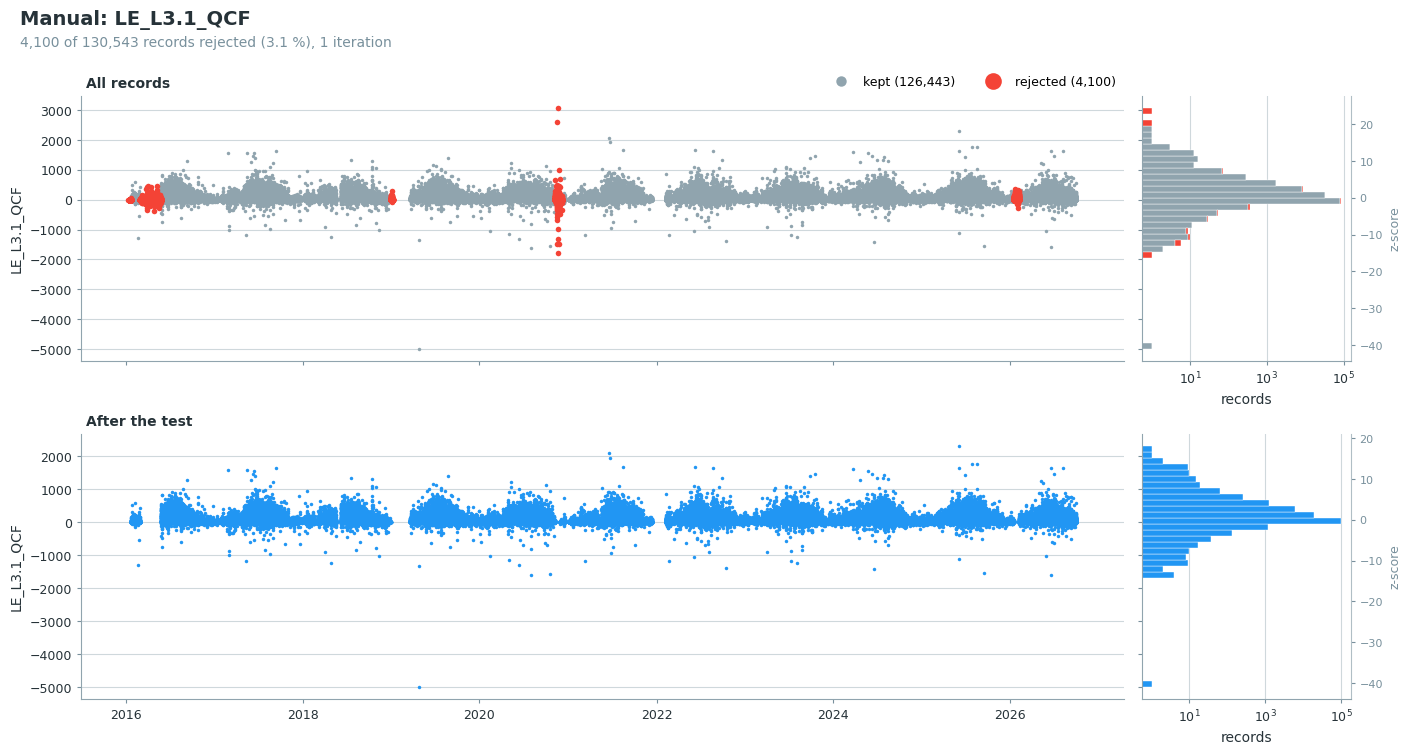

In [10]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [11]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

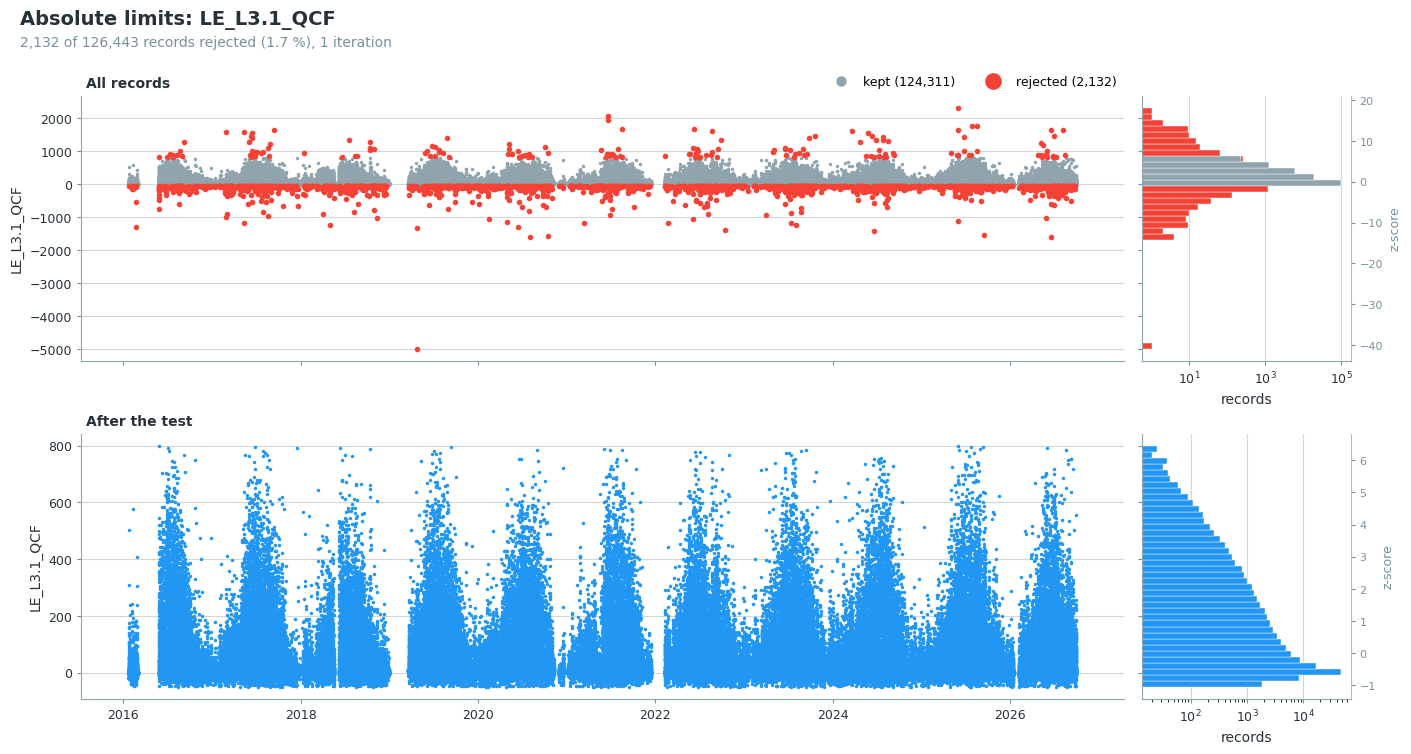

In [12]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [13]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2364 (  1.90%) | Day:   945 | Night:  1419

[Dt/Nt] ITER #02 | Outliers:   345 (  0.28%) | Day:   125 | Night:   220

[Dt/Nt] ITER #03 | Outliers:    60 (  0.05%) | Day:    20 | Night:    40

[Dt/Nt] ITER #04 | Outliers:    12 (  0.01%) | Day:     3 | Night:     9

[Dt/Nt] ITER #05 | Outliers:     4 (  0.00%) | Day:     0 | Night:     4

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

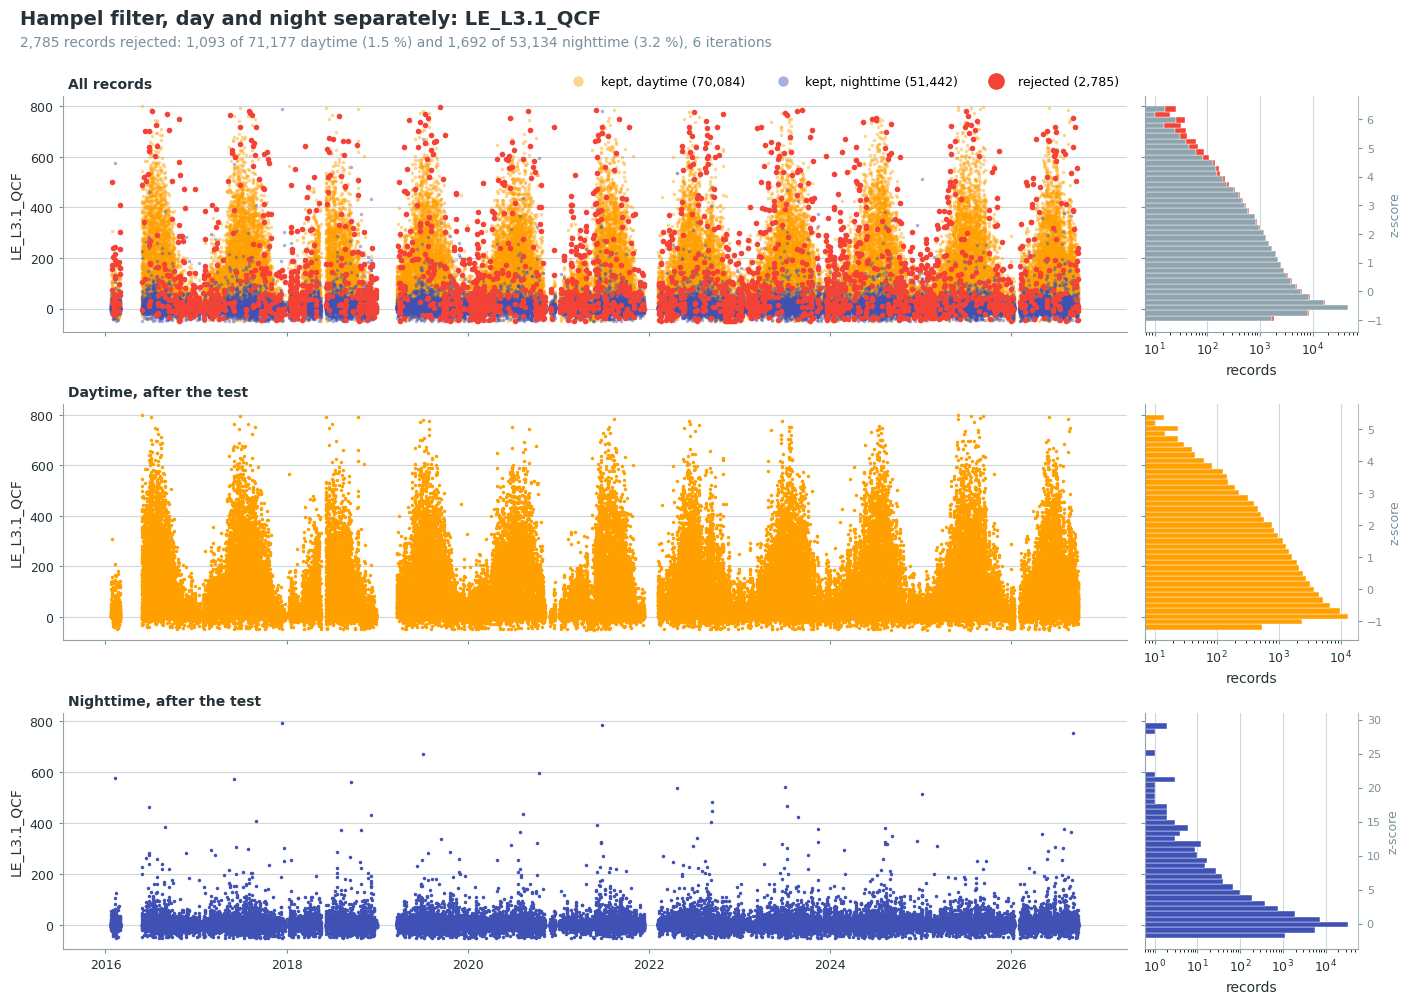

In [14]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2120 (  1.74%) | Day:   655 | Night:  1465

[Dt/Nt] ITER #02 | Outliers:   263 (  0.22%) | Day:    68 | Night:   195

[Dt/Nt] ITER #03 | Outliers:    58 (  0.05%) | Day:    16 | Night:    42

[Dt/Nt] ITER #04 | Outliers:     7 (  0.01%) | Day:     2 | Night:     5

[Dt/Nt] ITER #05 | Outliers:     1 (  0.00%) | Day:     0 | Night:     1

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

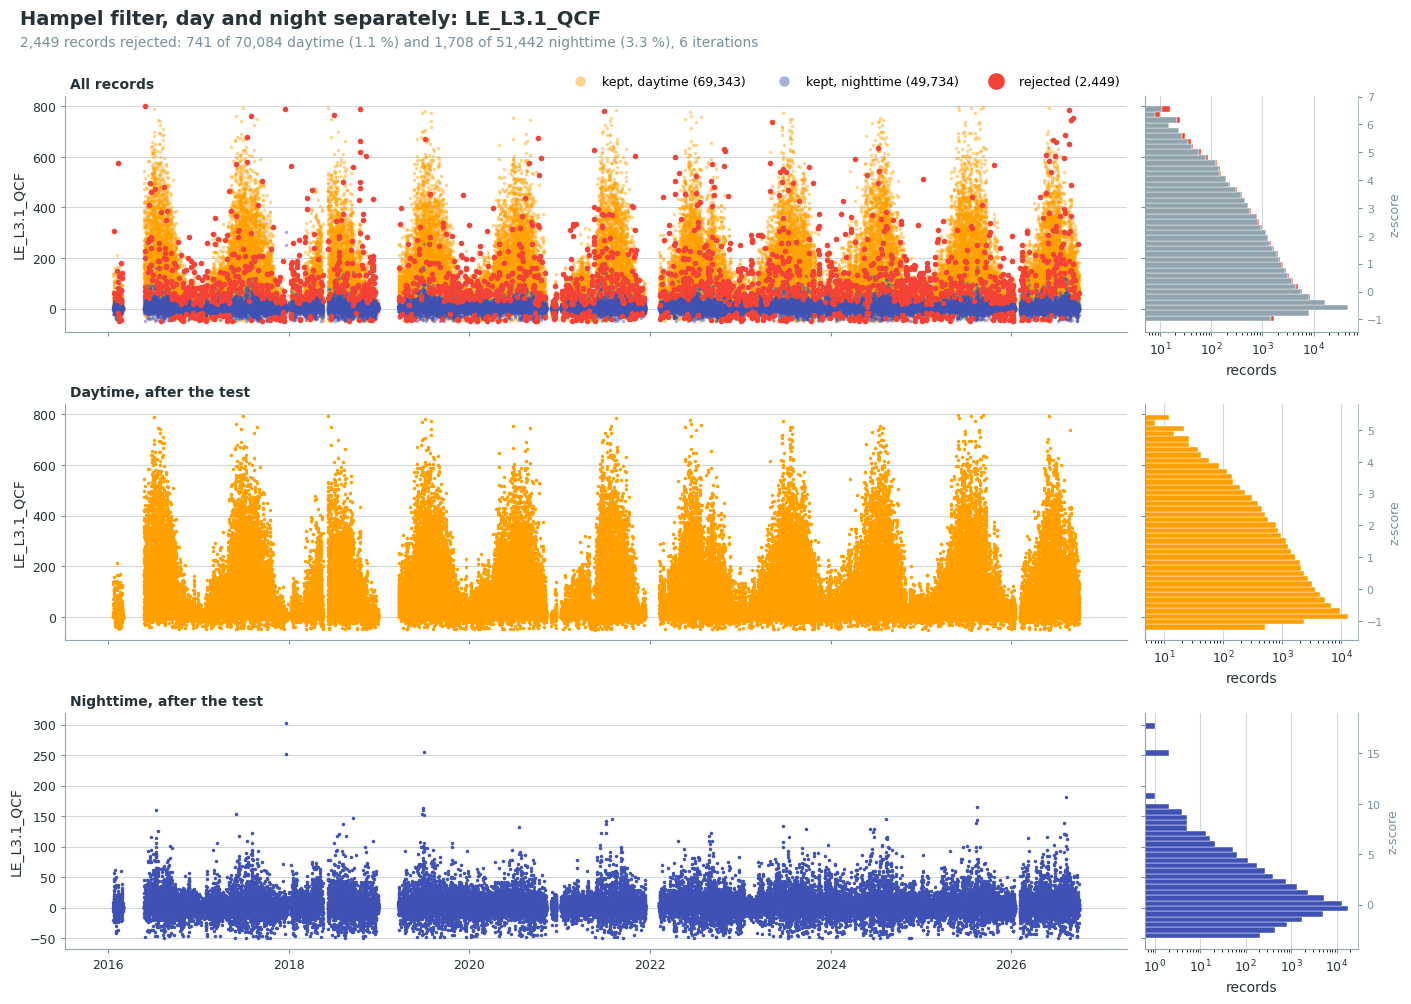

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [18]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [19]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 119,077 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

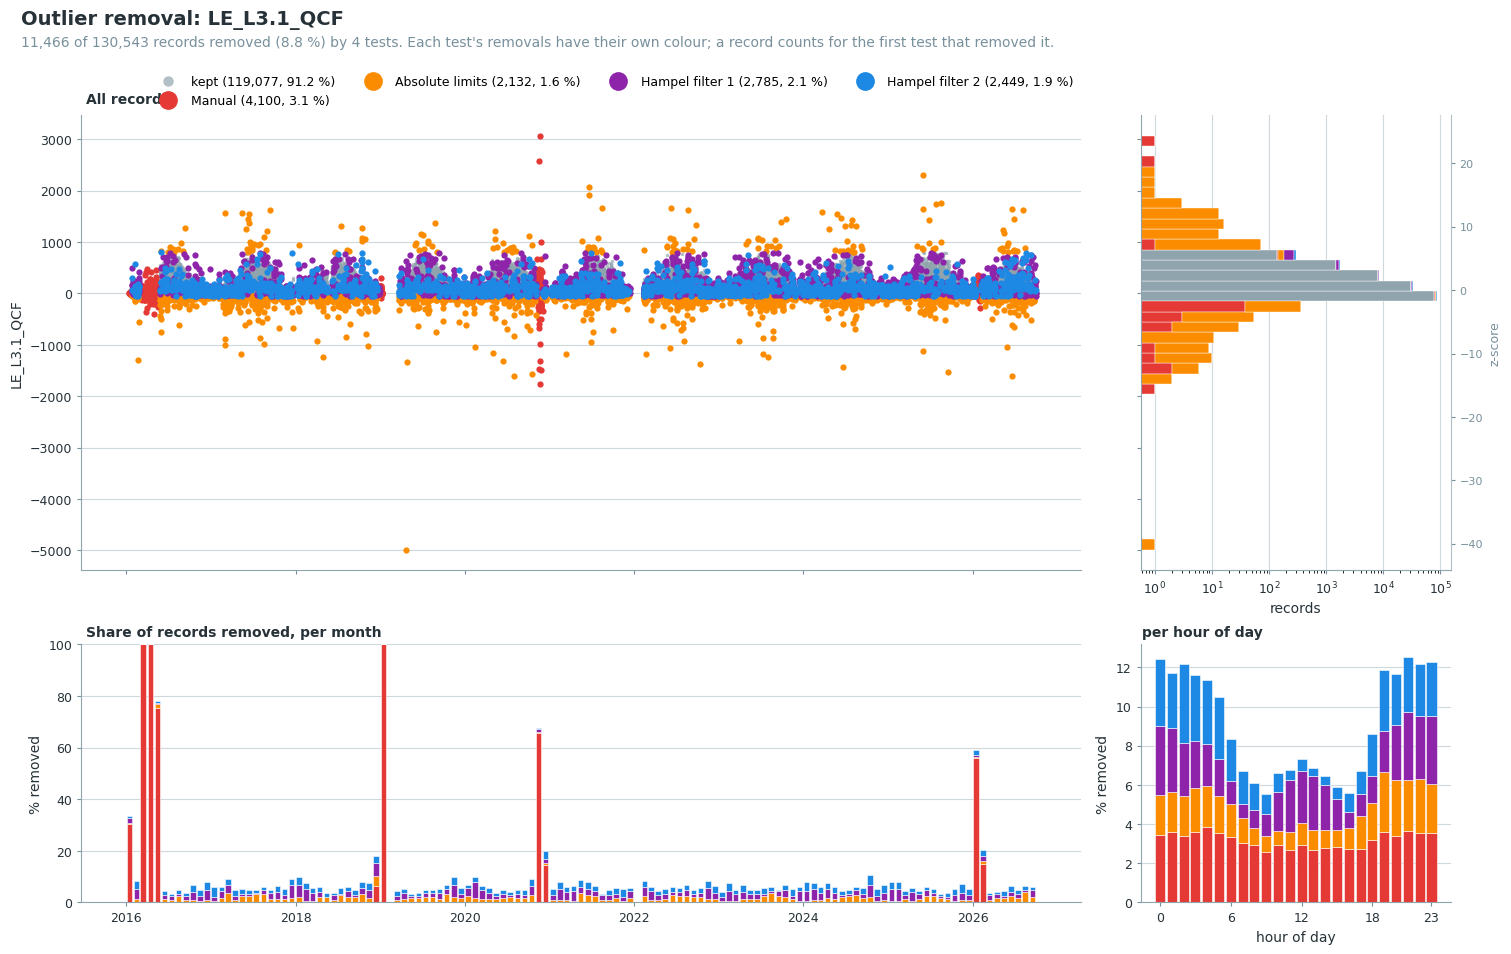

In [20]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

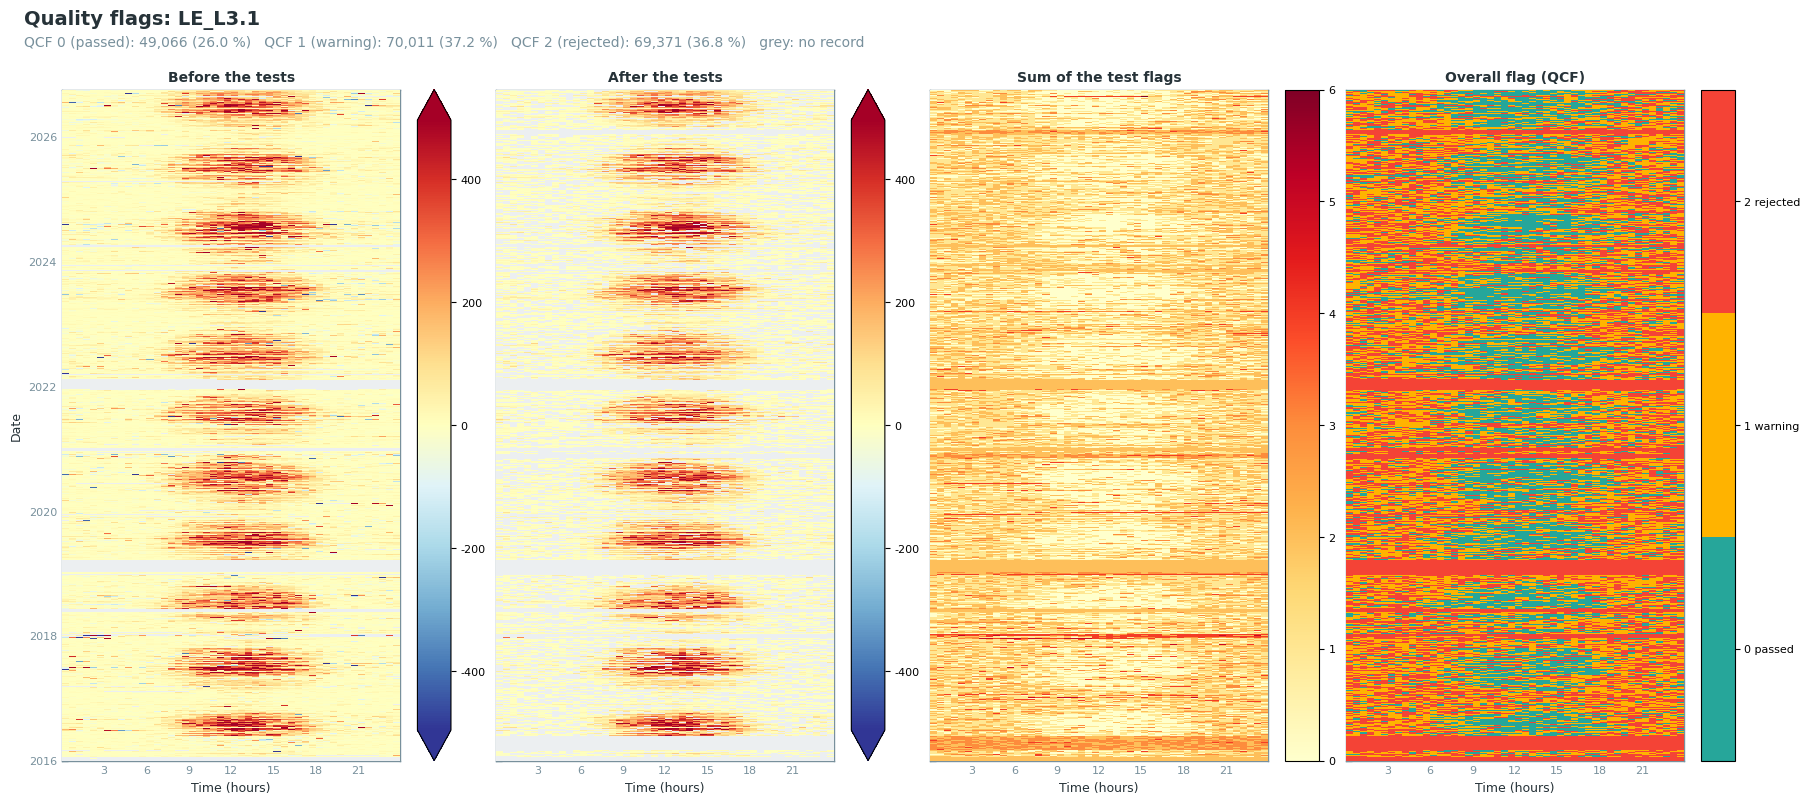

In [21]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [22]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: LE_L3.1
Measured records: 174,988 of 188,448
Missing records: 13,460 (7.14 %), flagged by the missing-values test
                                                          Pass     Warn     Fail    Fail      Not
Test                                Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                         all      174,988    52,194   80,020   42,774   24.44        0
                                    day       88,841    38,869   35,939   14,033   15.80        0
                                    night     86,147    13,325   44,081   28,741   33.36        0
                                                                                                 
L2_LE_SCF                           all      174,988   169,971    4,613      404    0.23        0
                                    day       88,841    86,446    2,170      225    0.25        0
                                    night     86,147    83,525    2,443      179    0.21        0
                                                                                                 
L2_LE_SIGNAL_STRENGTH               all      174,988   173,685        0    1,303    0.74        0
                                    day       88,841    88,297        0      544    0.61        0
                                    night     86,147    85,388        0      759    0.88        0
                                                                                                 
L2_LE_H2O_VM97_SPIKE_HF             all      174,988   173,870        0    1,118    0.64        0
                                    day       88,841    88,376        0      465    0.52        0
                                    night     86,147    85,494        0      653    0.76        0
                                                                                                 
L2_LE_H2O_VM97_DROPOUT_HF           all      174,988   174,988        0        0    0.00        0
                                    day       88,841    88,841        0        0    0.00        0
                                    night     86,147    86,147        0        0    0.00        0
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_MANUAL     all      130,543   126,443        0    4,100    3.14   44,445
                                    day       74,040    72,056        0    1,984    2.68   14,801
                                    night     56,503    54,387        0    2,116    3.74   29,644
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM     all      126,443   124,311        0    2,132    1.69   48,545
                                    day       72,056    71,177        0      879    1.22   16,785
                                    night     54,387    53,134        0    1,253    2.30   31,760
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL     all      124,311   121,526        0    2,785    2.24   50,677
                                    day       71,177    70,084        0    1,093    1.54   17,664
                                    night     53,134    51,442        0    1,692    3.18   33,013
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2   all      121,526   119,077        0    2,449    2.02   53,462
                                    day       70,084    69,343        0      741    1.06   18,757
                                    night     51,442    49,734        0    1,708    3.32   34,705

## Step 5: no USTAR filter (Level 3.3)

USTAR filtering is not applied to LE, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020): it
has not been shown that the advection that biases the CO2 flux under weak turbulence also affects
the energy fluxes, and the energy fluxes are small when advection is large, at night. The
gap-filling of the chain requires Level 3.3, and diive offers no other way to skip it. Level 3.3
therefore runs with a single scenario, `CUT_NONE`, at a threshold of 0 m s-1, the setting that
diive documents for H and LE. A threshold of 0 removes no record, also none without a USTAR value.
`CUT_NONE` appears in the column names from here on, and `data.filteredseries` is empty, as after
any Level 3.3.

In [23]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

After Level 3.3 every measured record that failed a test is removed; Level 3.3 itself removes
nothing here. What is left depends on the quality flags that are accepted
(`DAYTIME_ACCEPT_QCF_BELOW` and `NIGHTTIME_ACCEPT_QCF_BELOW`, here 2, so QCF 0 and 1). These records
are what the gap-filling starts from.

The highest-quality records (QCF 0) passed every test without a warning. Use them for analyses that
need measured values only, without gap-filled ones. The output file holds them in the column ending
in `_L3.3_CUT_NONE_QCF0`; the records for gap-filling are in the column ending in
`_L3.3_CUT_NONE_QCF`.

### 📋 Table: records for gap-filling

In [24]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:              used:    used:    used:    used:
USTAR      measured      tests      USTAR      used    QCF 0    QCF 1      day    night
───────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    174,988     55,911          0   119,077   49,066   70,011   69,343   49,734
                93%        30%         0%       63%      26%      37%      37%      26%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

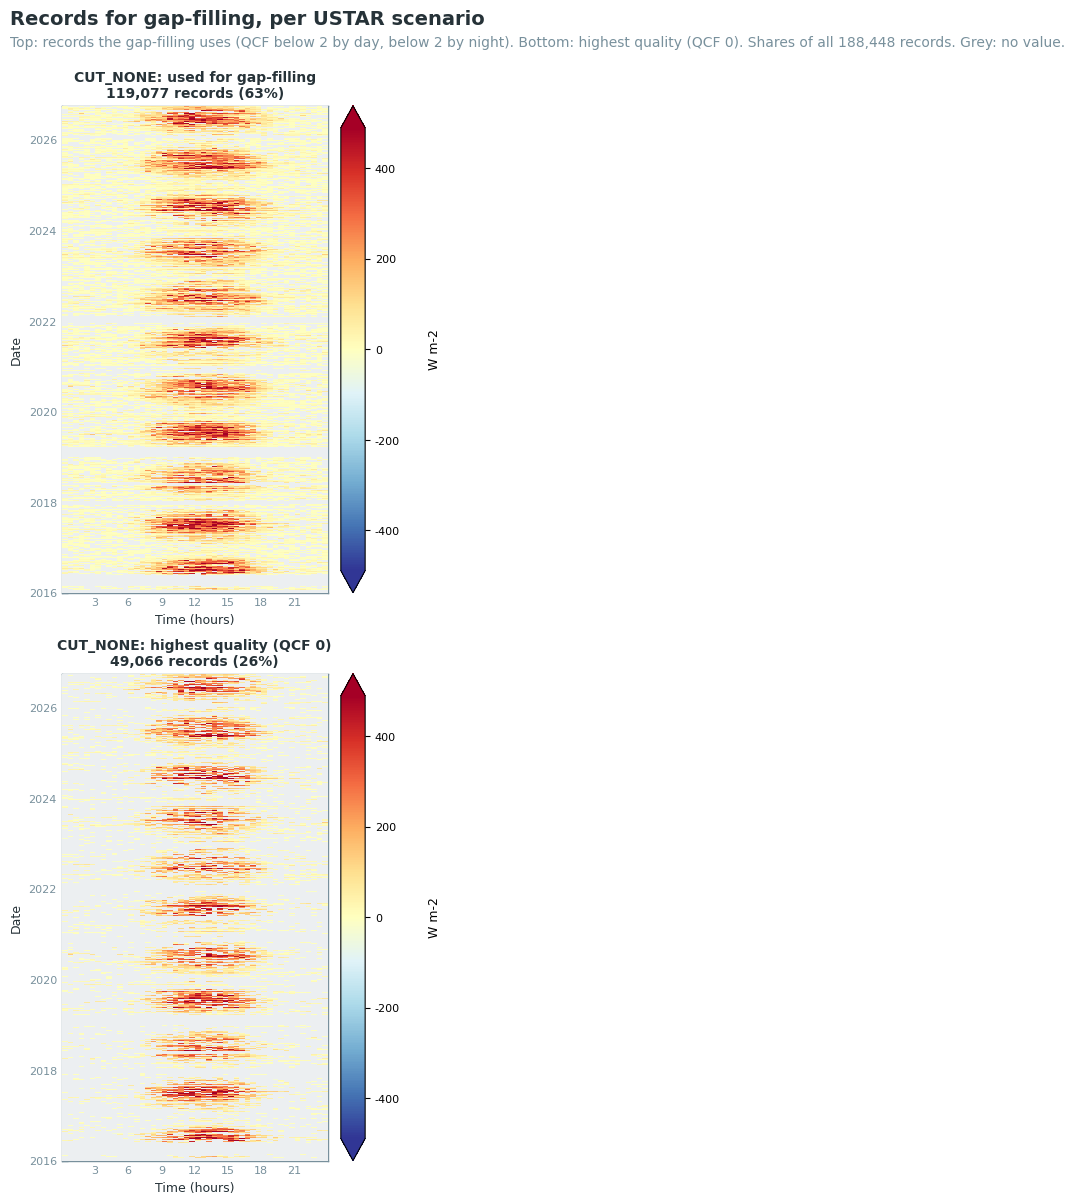

In [25]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [26]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        36.8   27743          30                 86.0           Jan                    57.8
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [27]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

Two methods fill the gaps: XGBoost, the method of this dataset, and MDS, the method FLUXNET2015 and
ONEFlux use for LE (Pastorello et al. 2020). The output file holds both. Step 10 compares them.

### XGBoost

Each year gets its own model, trained on that year and its two neighbouring years. SHAP values
select the features: a feature is kept if it is clearly more important than a random variable.

In [28]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) fills each gap with the mean of measured
fluxes under similar conditions: incoming radiation, air temperature and VPD within set
tolerances, in a time window that widens until enough similar records are found. `mode='diive'`
takes a symmetric mean by day (Vekuri et al. 2023) and fills every gap, also long ones, because
this dataset needs complete years. Only measured driver values serve as similar records (the
`ISFILLED` flags of the drivers). MDS predicts each measured record without using it, so its
scores are out-of-sample.

**Skipped** when `RUN_MDS = False`.

In [29]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of LE in MJ m-2
(W m-2 times 1800 s per half-hour), for each gap-filling method. In 2016 about 108 days have no
measurements (see the per-year plot in Step 10), so its sum rests largely on the model. 2019 has no
measurements from 30 December 2018 to 20 March 2019. 2026 ends on 30 September.

### 📋 Table: measured and filled records

In [30]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured   filled   filled %
───────────────────────────────────────────────────────────
MDS       CUT_NONE   188,448    119,077   69,371       36.8
XGBoost   CUT_NONE   188,448    119,077   69,371       36.8
MDS (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of LE

In [31]:
report_annual_sums(data, gain=W_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
                 MDS       XGBoost
year        CUT_NONE      CUT_NONE
──────────────────────────────────
2016     1,588 (49%)   1,494 (49%)
2017     1,526 (64%)   1,527 (64%)
2018     1,433 (63%)   1,422 (63%)
2019     1,450 (55%)   1,483 (55%)
2020     1,479 (61%)   1,493 (61%)
2021     1,351 (65%)   1,356 (65%)
2022     1,529 (63%)   1,538 (63%)
2023     1,595 (70%)   1,601 (70%)
2024     1,549 (68%)   1,555 (68%)
2025     1,607 (71%)   1,618 (71%)
2026 *   1,400 (68%)   1,424 (68%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. Early stopping uses a part of the training data, not the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [32]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2016   0.822   45.14   26.04   12.44   413.5
XGBoost   CUT_NONE   2017   0.822   45.14   26.04   12.44   413.5
XGBoost   CUT_NONE   2018   0.798   48.28   27.11   12.54   481.0
XGBoost   CUT_NONE   2019   0.804   46.89   27.03   13.10   517.8
XGBoost   CUT_NONE   2020   0.811   47.48   27.18   12.59   428.7
XGBoost   CUT_NONE   2021   0.797   47.30   27.02   12.93   582.3
XGBoost   CUT_NONE   2022   0.779   51.09   28.24   12.51   464.8
XGBoost   CUT_NONE   2023   0.807   47.51   27.24   12.34   395.8
XGBoost   CUT_NONE   2024   0.816   47.69   26.53   11.27   418.9
XGBoost   CUT_NONE   2025   0.801   50.00   27.96   12.23   488.3
XGBoost   CUT_NONE   2026   0.801   50.00   27.96   12.23   488.3
XGBoost   CUT_NONE   mean   0.805   47.87   27.12   12.42   463.0
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees early stopping chose, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [33]:
report_model_overview(data);

Gap-filling models
                trained                                         final    test   test            fal…
USTAR     ye…   on          featur…    train   test     trees     fit      R²   RMSE   filled   back
────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NO…   20…   2016-2018        86   23,127   7,7…   140/350   30,8…   0.822   45.…    8,995      0
CUT_NO…   20…   2016-2018        86   23,127   7,7…   140/350   30,8…   0.822   45.…    6,313      0
CUT_NO…   20…   2017-2019        86   23,927   7,9…   177/350   31,9…   0.798   48.…    6,463      0
CUT_NO…   20…   2018-2020        86   23,610   7,8…   161/350   31,4…   0.804   46.…    7,881      0
CUT_NO…   20…   2019-2021        86   23,910   7,9…   141/350   31,8…   0.811   47.…    6,783      0
CUT_NO…   20…   2020-2022        86   24,912   8,3…   168/350   33,2…   0.797   47.…    6,063      0
CUT_NO…   20…   2021-2023        86   25,956   8,6…   157/350   34,6…   0.779   51.…    6,545      0
CUT_NO…   20…   2022-2024        86   26,292   8,7…   102/350   35,0…   0.807   47.…    5,343      0
CUT_NO…   20…   2023-2025        86   27,341   9,1…   186/350   36,4…   0.816   47.…    5,664      0
CUT_NO…   20…   2024-2026        86   24,905   8,3…   123/350   33,2…   0.801   50.…    5,146      0
CUT_NO…   20…   2024-2026        86   24,905   8,3…   123/350   33,2…   0.801   50.…    4,175      0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, 
which the model did not see.
trees: with early stopping, the number it chose on 10 % of the training records, out of the maximum;
at the maximum, more trees might still help.
final fit: the gaps are filled by a model refitted on all complete records with that number of 
trees. filled / fallback: gaps of the model year filled by this model, or by the fallback model on 
timestamp features where a driver was missing.
XGBoost: early_stopping_rounds=10, learning_rate=0.05, max_depth=6, n_estimators=350, n_jobs=-1, 
random_state=42

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [34]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.746   55.32   31.13   13.71   657.0
XGBoost   CUT_NONE   2016   0.885   37.00   22.55   11.73   330.1
XGBoost   CUT_NONE   2017   0.885   37.00   22.55   11.73   330.1
XGBoost   CUT_NONE   2018   0.886   36.38   22.55   12.22   404.7
XGBoost   CUT_NONE   2019   0.875   37.26   22.81   12.40   445.6
XGBoost   CUT_NONE   2020   0.874   38.76   23.06   11.89   433.4
XGBoost   CUT_NONE   2021   0.873   37.87   22.65   11.62   427.6
XGBoost   CUT_NONE   2022   0.870   38.16   22.74   11.43   449.3
XGBoost   CUT_NONE   2023   0.859   40.60   24.23   12.01   376.2
XGBoost   CUT_NONE   2024   0.892   36.58   21.74   10.70   407.5
XGBoost   CUT_NONE   2025   0.872   40.51   24.08   11.95   375.7
XGBoost   CUT_NONE   2026   0.872   40.51   24.08   11.95   375.7
XGBoost   CUT_NONE   mean   0.877   38.24   23.00   11.79   396.0
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [35]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [36]:
report_gapfilling_feature_importances(data, ustar_scenario=USTAR_SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 86 features, mean |SHAP|
 #   fea…    2016   2017    2018   2019    2020   2021    2022   2023    2024   2025    2026    mean
────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .SW…   32.0…   32.…   26.9…   21.…   25.4…   29.…   27.6…   24.…   26.6…   30.…   30.2…   27.9…
 2   SW_…   24.5…   24.…   24.0…   26.…   23.4…   22.…   26.5…   30.…   22.7…   22.…   22.4…   24.4…
 3   .SW…   2.497   2.4…   6.963   11.…   11.6…   9.6…   8.153   9.5…   8.674   9.3…   9.301   8.169
 4   .DO…   6.443   6.4…   6.181   9.6…   2.886   2.0…   1.418   2.6…   4.247   7.9…   7.910   5.252
 5   .SW…   4.288   4.2…   2.981   1.8…   3.105   4.8…   3.001   1.8…   3.938   9.2…   9.258   4.422
 6   .TA…   4.668   4.6…   2.943   1.9…   3.576   8.3…   4.718   2.6…   2.416   1.8…   1.846   3.600
 7   .VP…   2.158   2.1…   2.718   3.2…   2.907   2.8…   2.746   3.4…   3.100   3.4…   3.438   2.933
 8   .DO…   3.097   3.0…   2.221   2.1…   2.703   3.5…   3.439   1.1…   1.666   3.2…   3.244   2.681
 9   .VP…   0.789   0.7…   1.460   4.6…   2.789   3.0…   2.258   1.9…   4.345   1.3…   1.301   2.240
10   .SW…   2.167   2.1…   1.738   1.7…   1.503   1.9…   4.293   2.6…   2.019   2.1…   2.136   2.234

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

> MDS (CUT_NONE): no feature ranks available.

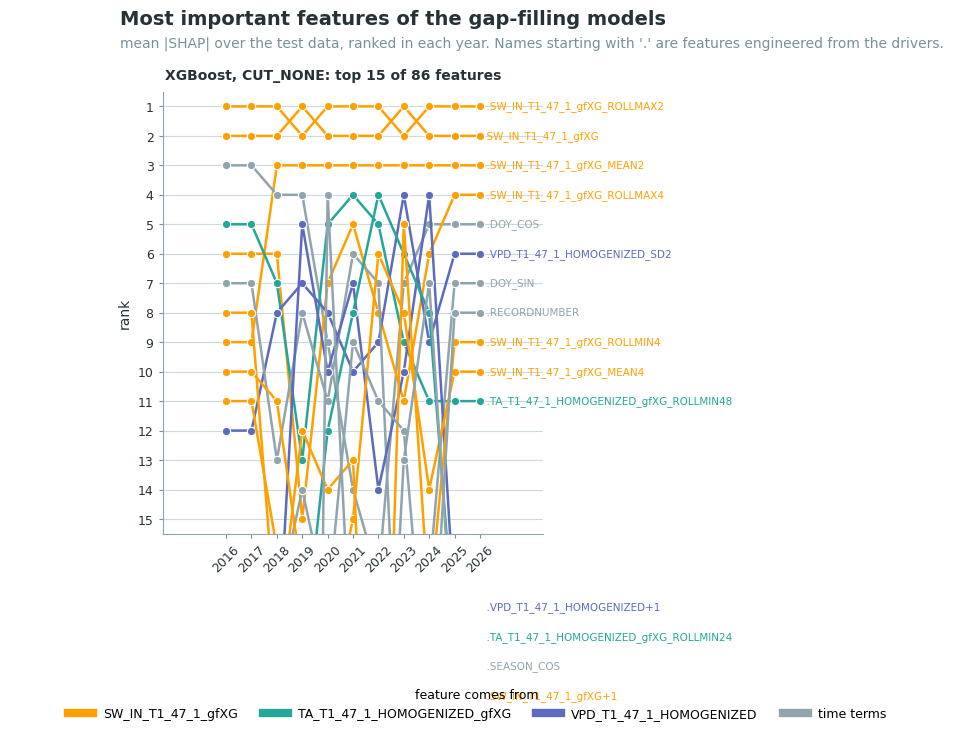

In [37]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: LE by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

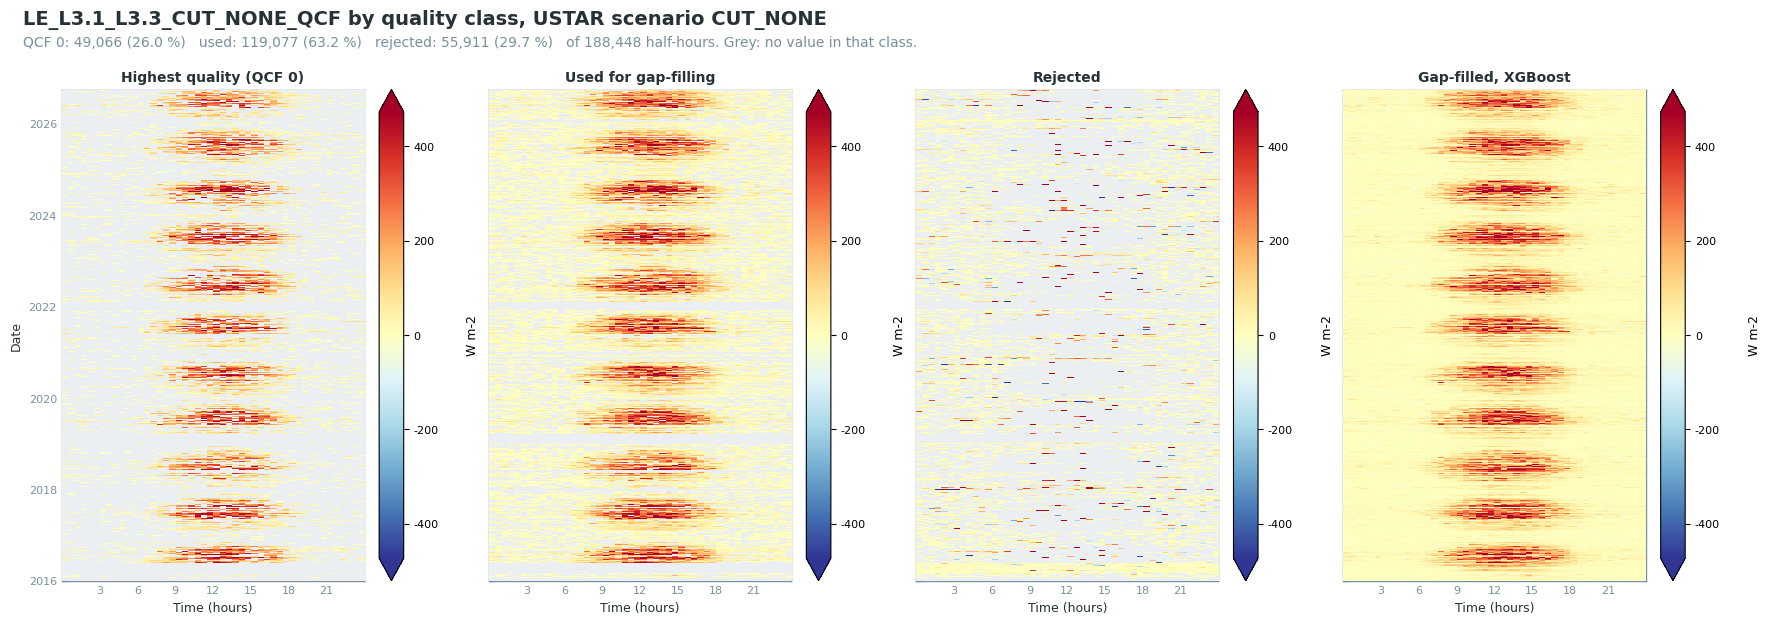

In [38]:
plot_quality_heatmaps(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: LE by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

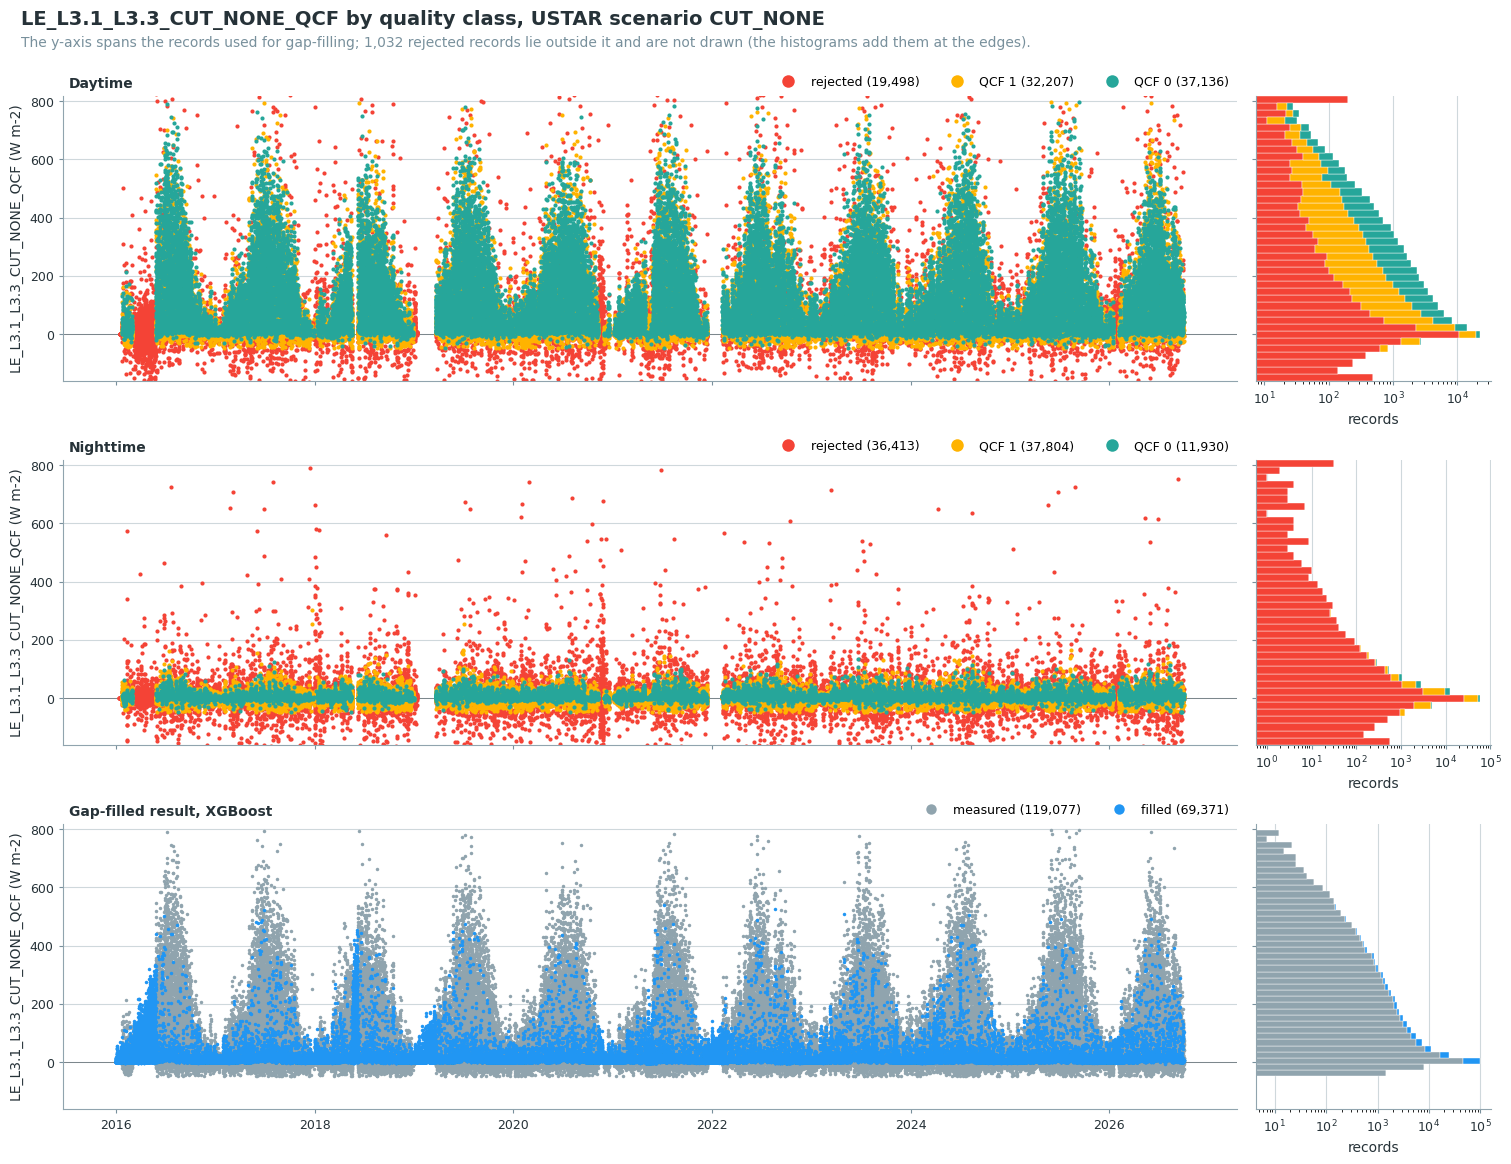

In [39]:
plot_quality_timeseries(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled LE

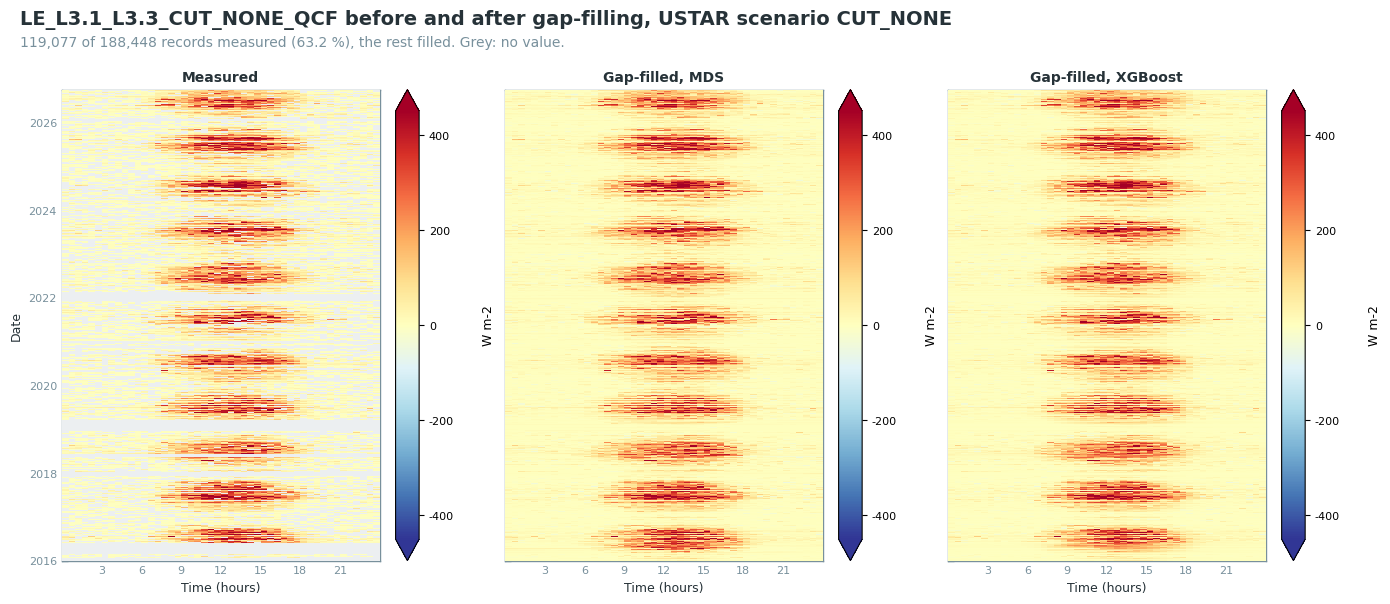

In [40]:
data.plot_gapfilled_heatmaps(ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS)

### 📊 Plot: cumulative LE

One line per gap-filling method, and the measured records alone (gaps counted as zero).

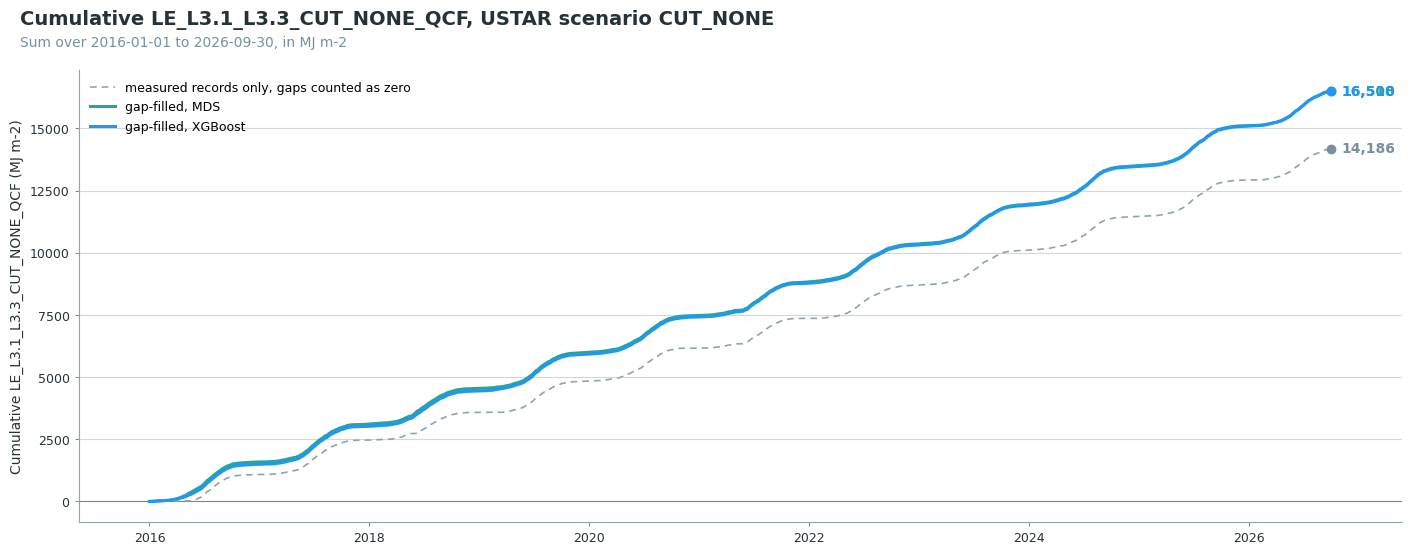

In [41]:
data.plot_cumulative_comparison(
    ustar_scenario=USTAR_SCENARIO,
    conv_factor=W_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative LE per year

One panel per gap-filling method, on the same y-axis. One line per year, with the mean of all years
plus and minus one standard deviation as a band. In 2016 about 108 days have no measurements: 1 to
10 January, before the first record, and 11 to 22 January and 1 March to 25 May, the start-up
periods removed by hand. These include the leaf-out in spring. The model fills them and learns that
season from 2017 and 2018. 2026 ends on 30 September, so its total cannot be compared with full
years, and it is left out of the mean and the band.

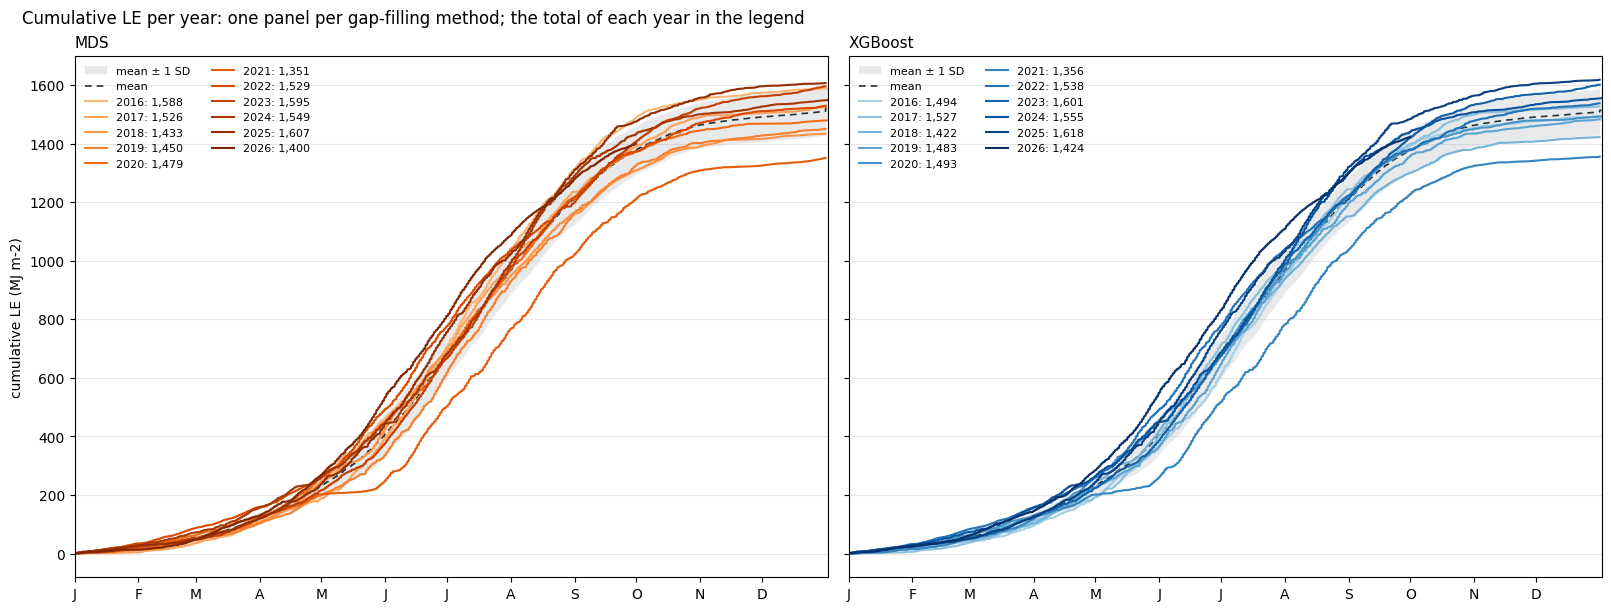

In [42]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_cmaps = {'mds': 'Oranges', 'xgb': 'Blues', 'rf': 'Greens'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[USTAR_SCENARIO]] * W_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(_cmaps.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color='#b0b8c0',
                         alpha=0.3, linewidth=0, label='mean ± 1 SD')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color='#263238', linewidth=1.2,
                 linestyle=(0, (4, 3)), label='mean')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.set_title(_names.get(_method, _method), loc='left', fontsize=11)
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.grid(axis='y', alpha=0.3)
    _ax.legend(frameon=False, fontsize=8, loc='upper left', ncol=1 if len(_years) < 8 else 2)
axes[0][0].set_ylabel('cumulative LE (MJ m-2)')
fig.suptitle('Cumulative LE per year: one panel per gap-filling method; the total of each year in '
             'the legend', x=0.01, ha='left', fontsize=12)
plt.show()

### Gap-filling methods compared

Both methods fill the same gaps, so the difference between their sums comes from the filled
values alone. The table splits that difference into daytime and nighttime gaps and by gap length,
and scores both methods on the same held-out records: the test records of XGBoost, which MDS also
predicts without using them. These are random single half-hours, so the scores describe short
gaps, while the sums depend more on the long ones.

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [43]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=W_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   16,508    16,510            1         14          -13     24     67      -2    -88
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 29,781 held-out records: MDS R² 0.75 RMSE 54.76, XGBoost R² 0.80 RMSE 47.99
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

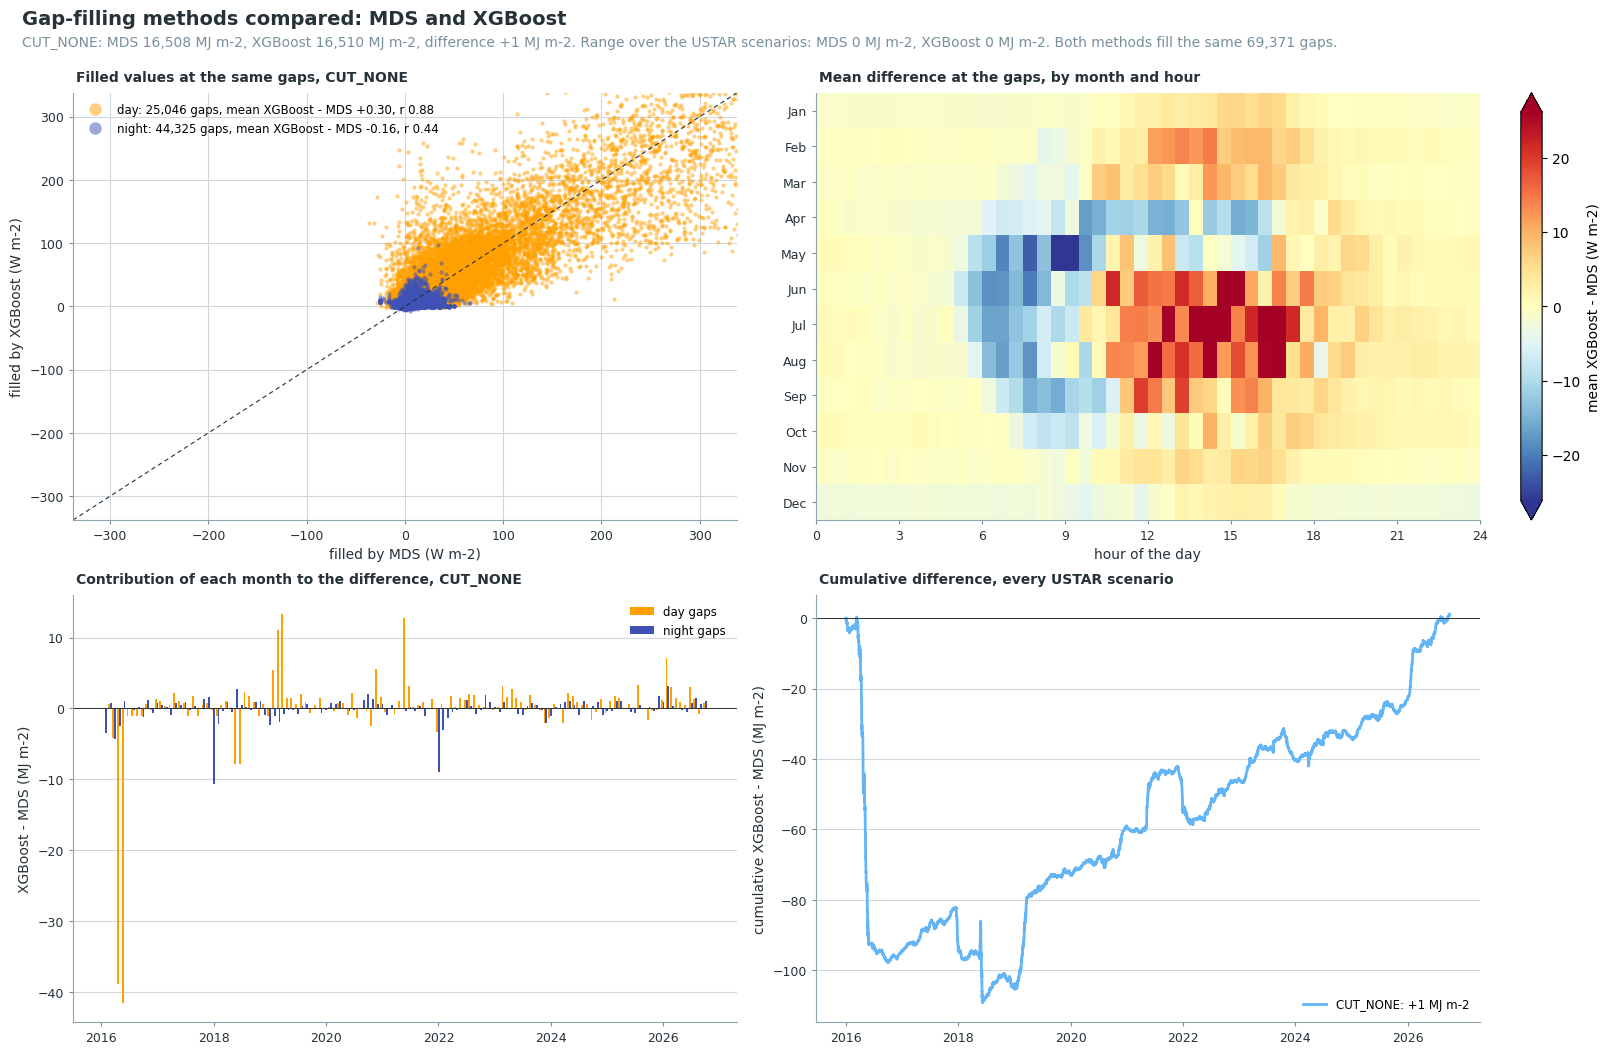

In [44]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=USTAR_SCENARIO, methods=('mds', 'xgb'),
                               gain=W_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## Step 11: evapotranspiration

Evapotranspiration (ET) is the water flux that corresponds to LE: LE divided by the latent heat of
vaporization, which depends on air temperature. FLUXNET2015 derives the water flux from LE in the
same way (Pastorello et al. 2020). `et_from_le` follows the R package bigleaf (`LE.to.ET`), with
the latent heat of vaporization λ = (2.501 - 0.00237 TA) × 10⁶ J kg-1 (Stull 1988, TA in °C), and
returns ET in mm h-1 (1 kg m-2 of water is 1 mm). TA is the complete air temperature driver
(`TA_F`), so every gap-filled record gets a value.

ET is computed from the gap-filled LE of each method. The ET columns hold the **amount per
half-hour in mm** (the rate in mm h-1 times 0.5), so they sum directly to daily or annual totals.
Their names are those of the LE series they come from, with `ET` in place of `LE`. They differ from
the input column `ET`, the EddyPro rate in mm h-1 of the measured records only.

### 📋 Table: ET columns

In [45]:
_ta = data.full_df[TA_F].reindex(data.fpc_df.index)
assert _ta.notna().all(), f"{TA_F} has gaps"
ET_COLS = {}  # {method: ET column}
_et = {}
for _method, _cols in data.gapfilled_cols().items():
    _le = data.fpc_df[_cols[USTAR_SCENARIO]]
    assert _le.name.startswith(FLUXCOL), _le.name
    _name = 'ET' + _le.name[len(FLUXCOL):]
    _et[_name] = et_from_le(le=_le, ta=_ta) * HOURS_PER_RECORD  # mm h-1 -> mm per half-hour
    ET_COLS[_method] = _name
ET_EXPORT = pd.DataFrame(_et)
assert ET_EXPORT.notna().all().all(), "a gap-filled record has no ET"

_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
display(pd.DataFrame({
    'from LE column': [data.gapfilled_cols()[_k][USTAR_SCENARIO] for _k in ET_COLS],
    'method': [_names.get(_k, _k) for _k in ET_COLS],
    'units': 'mm per half-hour',
    'records': [int(ET_EXPORT[_c].count()) for _c in ET_COLS.values()],
    'mean (mm d-1)': [round(float(ET_EXPORT[_c].mean()) * 48, 2) for _c in ET_COLS.values()],
}, index=pd.Index(list(ET_COLS.values()), name='ET column')))

,from LE column,method,units,records,mean (mm d-1)
ET column,,,,,
ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS,LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS,MDS,mm per half-hour,188448,1.71
ET_L3.1_L3.3_CUT_NONE_QCF_gfXG,LE_L3.1_L3.3_CUT_NONE_QCF_gfXG,XGBoost,mm per half-hour,188448,1.71


### 📋 Table: annual sums of ET

Annual sums in mm for each gap-filling method, and their difference. 2026 ends on 30 September.

In [46]:
ANNUAL_ET = ET_EXPORT.groupby(ET_EXPORT.index.year).sum()
ANNUAL_ET.columns = [_names.get(_k, _k) for _k in ET_COLS]
ANNUAL_ET.index.name = 'year'
if {'XGBoost', 'MDS'} <= set(ANNUAL_ET.columns):
    ANNUAL_ET['XGBoost - MDS'] = ANNUAL_ET['XGBoost'] - ANNUAL_ET['MDS']
print("Annual sums of ET (mm)")
display(ANNUAL_ET.round(1))

Annual sums of ET (mm)


,MDS,XGBoost,XGBoost - MDS
year,,,
2016,645.6,607.3,-38.3
2017,620.8,621.3,0.4
2018,583.2,578.4,-4.8
2019,589.7,602.9,13.2
2020,601.2,606.7,5.5
2021,548.8,550.6,1.9
2022,621.7,625.2,3.5
2023,648.7,651.0,2.3
2024,629.5,632.1,2.6


### 📊 Plot: annual sums of ET

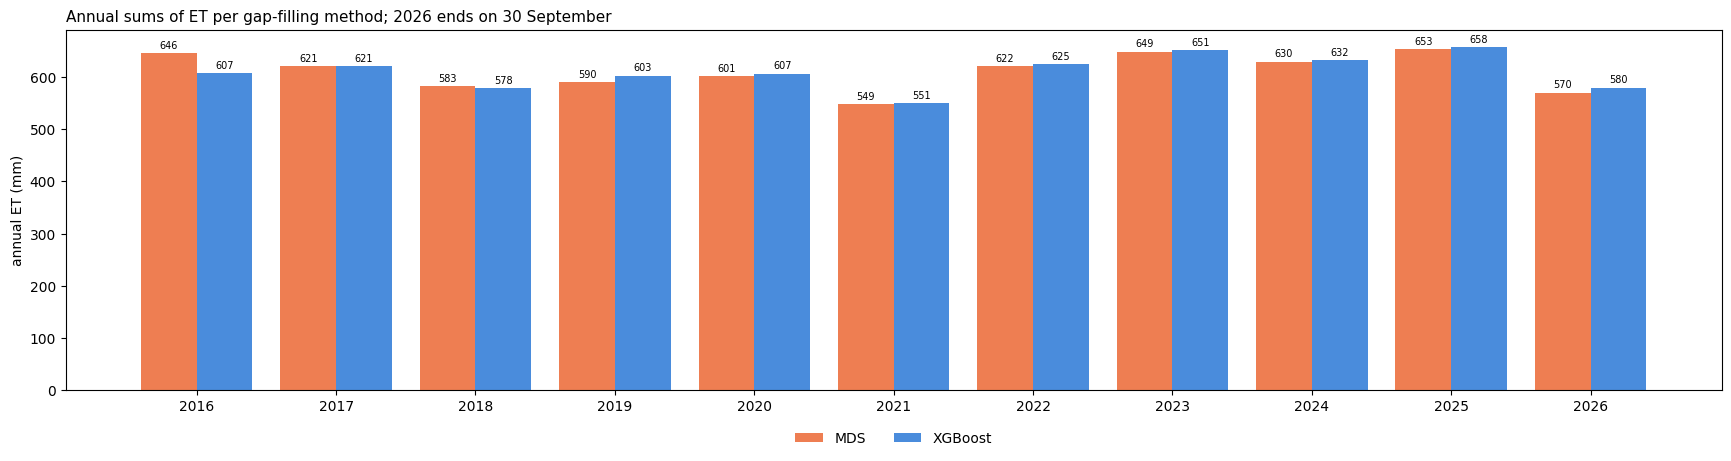

In [47]:
_colors = {'MDS': '#eb6834', 'XGBoost': '#2a78d6', 'random forest': '#2e9e5b'}
_methods = [_names.get(_k, _k) for _k in ET_COLS]
_years = ANNUAL_ET.index
_width = 0.8 / len(_methods)
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 4.5), layout='constrained')
for _i, _method in enumerate(_methods):
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, ANNUAL_ET[_method], _width, color=_colors.get(_method, 'grey'), alpha=0.85,
           label=_method)
    for _xi, _v in zip(_x, ANNUAL_ET[_method]):
        ax.annotate(f'{_v:.0f}', (_xi, _v), ha='center', va='bottom', fontsize=7,
                    xytext=(0, 2), textcoords='offset points')
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual ET (mm)')
ax.set_title(f'Annual sums of ET per gap-filling method; {_years[-1]} ends on '
             f'{ET_EXPORT.index[-1]:%d %B}', loc='left', fontsize=11)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(_methods))
plt.show()

## 💾 Step 12: export

The output file holds only what this notebook adds: every column the chain created and the ET
columns of Step 11. The input columns stay unchanged in the input file; the merge into the fullset
joins the outputs of the flux notebooks with it on the timestamp.

In [48]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(ET_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(ET_EXPORT.columns) <= set(out_df.columns), "ET columns missing from the output"
print(f"ET columns in the output: {list(ET_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

ET columns in the output: ['ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS', 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG']
188,448 records x 45 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\11_FPPC_IRGA72_LE_2016-2026.09.parquet (0.280 seconds).

***

# End of notebook.

In [49]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-26 15:44:15
Finished: 2026-10-26 15:47:01
Runtime:  00:02:46 (hh:mm:ss)
